In [1]:
import pandas as pd
import numpy as np
import mobipy
import mobipy.optim as opt
import pickle as pkl
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

In [2]:
mobipy.allow_logging(False) # Suppress warnings

In [3]:
model = '../models/simplyq_arctic.txt'
base_dir = '../data/adventelva/'

params = base_dir + 'adventelva_simplyn_quickflow_new_n.dat'
#result_file = base_dir + 'adventelva_quickflow_optimized.dat'
    
app = mobipy.Model_Application.build_from_model_and_data_file(
    model,
    params
)

app.run()

dates = app.var('Daily mean reach flow')['Adventelva'].index
timesteps = len(dates)

In [4]:
simple_setup = False # Must be false since that is how we ran the MCMC

par_dict = {
    'temp_lapse' : ('ArcticAtmosphere', 'temp_lapse_rate', [], -0.0098, -0.0028),
    'ddf_snow' : ('ArcticSnow', 'ddf0_melt', [], 1, 5),
    'ddf_ice' : ('SimplyGlacier', 'ddf_ice', [], 3, 12),
    'tc_s' : ('SimplyPermafrostFlow', 'tc_s', [], 0.1, 2)
}
if not simple_setup :
    par_dict |= {
        'refr' : ('ArcticSnow', 'refr_eff', [], 0, 0.5),
        'liq' : ('ArcticSnow', 'snow_liq', [], 0, 0.4),
        'ald' : ('ArcticSnow', 'ald_max_infiltration', [], 0, 1000)
    }
params, set_params = opt.params_from_dict(app, par_dict)

In [5]:
with open("mc_results.pkl", "rb") as f:
    mc_res = pkl.load(f)

In [11]:
# NOTE: Burnin is already removed from chains
chain = mc_res['res'].chain
n_steps, n_walkers, n_pars = chain.shape
assert(n_pars == len(par_dict)+2)

def resample_pars(data, i) :
    par = params.copy()
    sample = chain[i%50, i//50, :]
    for j, p in enumerate(params) :
        par[p].set(value=sample[j])
    set_params(data, par)

In [27]:
n_resamples = 1000

rng = np.random.default_rng()
draws = rng.integers(0, n_steps*n_walkers, size=n_resamples)

results = np.zeros((n_resamples, timesteps))

def single_run(i) :
    data = app.copy()
    resample_pars(data, i)
    data.run()
    #results[i, :] = data.var('Daily mean reach flow')['Adventelva']
    results[i, :] = data.var('Glacier ice')['Adventelva', 'Glacier2_250']
    del data
    return None

_ = Parallel(n_jobs=-1, verbose=1, backend='threading')(map(delayed(single_run), range(n_resamples)))

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    8.2s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   29.4s
[Parallel(n_jobs=-1)]: Done 776 tasks      | elapsed:   59.9s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  1.3min finished


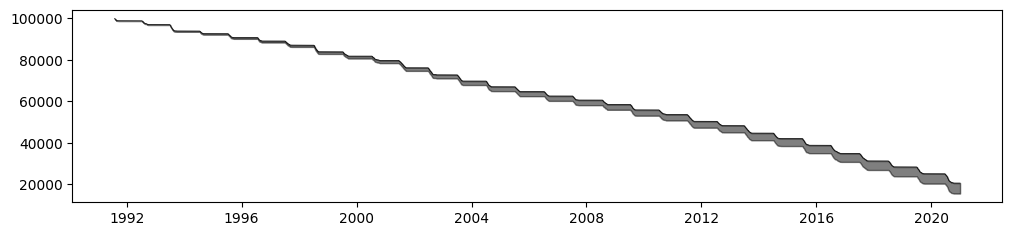

In [29]:
quantiles = [0.025, 0.5, 0.975]
quants = np.quantile(results, quantiles, axis=0)

start_dt = '1980-01-01'
end_dt = '2020-12-31'
filt = (dates >= start_dt) & (dates <= end_dt)

fig, ax = plt.subplots(1, 1, figsize=(12, 2.5))

ax.fill_between(dates[filt], quants[0][filt], quants[1][filt], color='k', alpha=0.5) # upper and lower percentile
ax.plot(dates[filt], quants[1][filt], color='k', linewidth=0.5) # median
